## Excel Data

### Data Input

In [173]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = Path("../data/Story.xlsx")  # Change if needed
sheet_name = "Table_3"

# Read without assuming any row is a header
raw = pd.read_excel(
    file_path,
    sheet_name=sheet_name,
)

print("Shape:", raw.shape)
print("Rows:", raw.shape[0])
print("Columns:", raw.shape[1])

display(raw.head(10))

Shape: (4040, 69)
Rows: 4040
Columns: 69


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Date,(all),2023,Q1 (2023),Jan (2023),Feb (2023),Mar (2023),...,Feb (2026),Mar (2026),Q2 (2026),Apr (2026),May (2026),Jun (2026),Q3 (2026),Jul (2026),Aug (2026),Sep (2026)
0,Business unit,SAC_Legal_Entity,ACCOUNT,Description,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7A,1700,PL,PROFIT & LOSS,-112579.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-112579.01,NaN,NaN,-112579.01
2,7A,1700,PL01,Sales Revenue,-335064.50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-335064.50,NaN,NaN,-335064.50
3,7A,1700,1010025,Frenchise Sales (Include Inter Company),-335064.50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-335064.50,NaN,NaN,-335064.50
4,7A,1700,PL02,Other Income,0.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.01,NaN,NaN,0.01
5,7A,1700,1030045,Unrealized Exchange Gain/Loss,0.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.01,NaN,NaN,0.01
6,7A,1700,PL03,Cost Of Sales,222368.73,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,222368.73,NaN,NaN,222368.73
7,7A,1700,2010000,COGS without Cost Element,220743.29,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,220743.29,NaN,NaN,220743.29
8,7A,1700,2040010,COGM - Finished Goods,-194324.54,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-194324.54,NaN,NaN,-194324.54
9,7A,1700,2050000,Third Party Consumption - Raw Material,153559.87,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,153559.87,NaN,NaN,153559.87


### Data Transformation to proper form

In [ ]:
# Extract column names from the first row and drop any NaN values
new_cols = raw.iloc[0].dropna().values
new_cols

array(['Business unit', 'SAC_Legal_Entity', 'ACCOUNT', 'Description'],
      dtype=object)

In [ ]:
# Create a mapping from old column names to new column names
mapper = dict(zip(raw.columns[:4], new_cols))
mapper

{'Unnamed: 0': 'Business unit',
 'Unnamed: 1': 'SAC_Legal_Entity',
 'Unnamed: 2': 'ACCOUNT',
 'Date': 'Description'}

In [176]:
raw.rename(columns=mapper, inplace=True)

In [177]:
raw.head(10)

,Business unit,SAC_Legal_Entity,ACCOUNT,Description,(all),2023,Q1 (2023),Jan (2023),Feb (2023),Mar (2023),...,Feb (2026),Mar (2026),Q2 (2026),Apr (2026),May (2026),Jun (2026),Q3 (2026),Jul (2026),Aug (2026),Sep (2026)
0,Business unit,SAC_Legal_Entity,ACCOUNT,Description,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7A,1700,PL,PROFIT & LOSS,-112579.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-112579.01,NaN,NaN,-112579.01
2,7A,1700,PL01,Sales Revenue,-335064.50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-335064.50,NaN,NaN,-335064.50
3,7A,1700,1010025,Frenchise Sales (Include Inter Company),-335064.50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-335064.50,NaN,NaN,-335064.50
4,7A,1700,PL02,Other Income,0.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.01,NaN,NaN,0.01
5,7A,1700,1030045,Unrealized Exchange Gain/Loss,0.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.01,NaN,NaN,0.01
6,7A,1700,PL03,Cost Of Sales,222368.73,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,222368.73,NaN,NaN,222368.73
7,7A,1700,2010000,COGS without Cost Element,220743.29,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,220743.29,NaN,NaN,220743.29
8,7A,1700,2040010,COGM - Finished Goods,-194324.54,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-194324.54,NaN,NaN,-194324.54
9,7A,1700,2050000,Third Party Consumption - Raw Material,153559.87,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,153559.87,NaN,NaN,153559.87


In [178]:
raw.drop(index=0, inplace=True)

In [179]:
raw.head(10)

,Business unit,SAC_Legal_Entity,ACCOUNT,Description,(all),2023,Q1 (2023),Jan (2023),Feb (2023),Mar (2023),...,Feb (2026),Mar (2026),Q2 (2026),Apr (2026),May (2026),Jun (2026),Q3 (2026),Jul (2026),Aug (2026),Sep (2026)
1,7A,1700,PL,PROFIT & LOSS,-112579.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-112579.01,NaN,NaN,-112579.01
2,7A,1700,PL01,Sales Revenue,-335064.50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-335064.50,NaN,NaN,-335064.50
3,7A,1700,1010025,Frenchise Sales (Include Inter Company),-335064.50,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-335064.50,NaN,NaN,-335064.50
4,7A,1700,PL02,Other Income,0.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.01,NaN,NaN,0.01
5,7A,1700,1030045,Unrealized Exchange Gain/Loss,0.01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.01,NaN,NaN,0.01
6,7A,1700,PL03,Cost Of Sales,222368.73,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,222368.73,NaN,NaN,222368.73
7,7A,1700,2010000,COGS without Cost Element,220743.29,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,220743.29,NaN,NaN,220743.29
8,7A,1700,2040010,COGM - Finished Goods,-194324.54,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-194324.54,NaN,NaN,-194324.54
9,7A,1700,2050000,Third Party Consumption - Raw Material,153559.87,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,153559.87,NaN,NaN,153559.87
10,7A,1700,2050025,Third Party Consumption - Finished Goods,40763.42,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,40763.42,NaN,NaN,40763.42


In [180]:
raw.fillna(0, inplace=True)

,Business unit,SAC_Legal_Entity,ACCOUNT,Description,(all),2023,Q1 (2023),Jan (2023),Feb (2023),Mar (2023),...,Feb (2026),Mar (2026),Q2 (2026),Apr (2026),May (2026),Jun (2026),Q3 (2026),Jul (2026),Aug (2026),Sep (2026)
1,7A,1700,PL,PROFIT & LOSS,-112579.01,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-112579.01,0.0,0.00,-112579.01
2,7A,1700,PL01,Sales Revenue,-335064.50,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-335064.50,0.0,0.00,-335064.50
3,7A,1700,1010025,Frenchise Sales (Include Inter Company),-335064.50,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-335064.50,0.0,0.00,-335064.50
4,7A,1700,PL02,Other Income,0.01,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.0,0.00,0.01
5,7A,1700,1030045,Unrealized Exchange Gain/Loss,0.01,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.0,0.00,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4035,US02,1100,PL03,Cost Of Sales,99828.07,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,99828.07,0.0,99828.07,0.00
4036,US02,1100,2010000,COGS without Cost Element,99828.07,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,99828.07,0.0,99828.07,0.00
4037,US02,1100,PL06,Advt. & Promotions,20134.22,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,20134.22,0.0,110.22,20024.00
4038,US02,1100,2270065,Freight & Forwarding On Sales,20024.00,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,20024.00,0.0,0.00,20024.00


### Final Transformed Data

In [181]:
raw.to_csv("../data/Story.csv", index=False)  # Save to CSV for easier access

## Creating Monthly Time Series Data for Darts

In [1]:
import pandas as pd
import numpy as np
import re

# Convert the four-level row index back into ordinary columns
df = pd.read_csv("../data/Story.csv")

# Clean dimension names
df.columns = [
    " ".join(str(x) for x in col if pd.notna(x)).strip()
    if isinstance(col, tuple) else str(col).strip()
    for col in df.columns
]

print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

display(df.head())

Shape: (4039, 69)
Columns:
['Business unit', 'SAC_Legal_Entity', 'ACCOUNT', 'Description', '(all)', '2023', 'Q1 (2023)', 'Jan (2023)', 'Feb (2023)', 'Mar (2023)', 'Q2 (2023)', 'Apr (2023)', 'May (2023)', 'Jun (2023)', 'Q3 (2023)', 'Jul (2023)', 'Aug (2023)', 'Sep (2023)', 'Q4 (2023)', 'Oct (2023)', 'Nov (2023)', 'Dec (2023)', '2024', 'Q1 (2024)', 'Jan (2024)', 'Feb (2024)', 'Mar (2024)', 'Q2 (2024)', 'Apr (2024)', 'May (2024)', 'Jun (2024)', 'Q3 (2024)', 'Jul (2024)', 'Aug (2024)', 'Sep (2024)', 'Q4 (2024)', 'Oct (2024)', 'Nov (2024)', 'Dec (2024)', '2025', 'Q1 (2025)', 'Jan (2025)', 'Feb (2025)', 'Mar (2025)', 'Q2 (2025)', 'Apr (2025)', 'May (2025)', 'Jun (2025)', 'Q3 (2025)', 'Jul (2025)', 'Aug (2025)', 'Sep (2025)', 'Q4 (2025)', 'Oct (2025)', 'Nov (2025)', 'Dec (2025)', '2026', 'Q1 (2026)', 'Jan (2026)', 'Feb (2026)', 'Mar (2026)', 'Q2 (2026)', 'Apr (2026)', 'May (2026)', 'Jun (2026)', 'Q3 (2026)', 'Jul (2026)', 'Aug (2026)', 'Sep (2026)']


,Business unit,SAC_Legal_Entity,ACCOUNT,Description,(all),2023,Q1 (2023),Jan (2023),Feb (2023),Mar (2023),...,Feb (2026),Mar (2026),Q2 (2026),Apr (2026),May (2026),Jun (2026),Q3 (2026),Jul (2026),Aug (2026),Sep (2026)
0,7A,1700,PL,PROFIT & LOSS,-112579.01,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-112579.01,0.0,0.0,-112579.01
1,7A,1700,PL01,Sales Revenue,-335064.50,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-335064.50,0.0,0.0,-335064.50
2,7A,1700,1010025,Frenchise Sales (Include Inter Company),-335064.50,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-335064.50,0.0,0.0,-335064.50
3,7A,1700,PL02,Other Income,0.01,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.0,0.0,0.01
4,7A,1700,1030045,Unrealized Exchange Gain/Loss,0.01,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.0,0.0,0.01


In [2]:
MONTH_PATTERN = re.compile(
    r"^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)"
    r"\s*\(\s*(\d{4})\s*\)$",
    re.IGNORECASE
)

def parse_month_column(column):
    """Return the month-start timestamp if this is a monthly column."""
    label = str(column).strip()
    match = MONTH_PATTERN.fullmatch(label)

    if not match:
        return None

    return pd.to_datetime(label, format="%b (%Y)", errors="coerce")


month_columns = {}
for col in df.columns:
    parsed_date = parse_month_column(col)
    if parsed_date is not None:
        month_columns[col] = parsed_date

monthly_cols = list(month_columns.keys())

print("Detected monthly columns:", len(monthly_cols))
print("First 15 monthly columns:")
print(monthly_cols[:15])

print("\nDetected date range:")
if month_columns:
    print(min(month_columns.values()), "to", max(month_columns.values()))
else:
    print("No monthly columns detected. Check the actual column names.")

Detected monthly columns: 45
First 15 monthly columns:
['Jan (2023)', 'Feb (2023)', 'Mar (2023)', 'Apr (2023)', 'May (2023)', 'Jun (2023)', 'Jul (2023)', 'Aug (2023)', 'Sep (2023)', 'Oct (2023)', 'Nov (2023)', 'Dec (2023)', 'Jan (2024)', 'Feb (2024)', 'Mar (2024)']

Detected date range:
2023-01-01 00:00:00 to 2026-09-01 00:00:00


In [3]:
# Numeric conversion for the monthly values
for col in monthly_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if monthly_cols:
    print("Monthly data quality:")
    print("Non-null cells:", int(df[monthly_cols].notna().sum().sum()))
    print("Non-zero cells:", int(df[monthly_cols].fillna(0).ne(0).sum().sum()))
    print("All-zero accounts:", int(
        df[monthly_cols].fillna(0).eq(0).all(axis=1).sum()
    ))

    display(
        df[["ACCOUNT", "Description"] + monthly_cols[:6]].head(15)
    )

Monthly data quality:
Non-null cells: 181755
Non-zero cells: 68519
All-zero accounts: 176


,ACCOUNT,Description,Jan (2023),Feb (2023),Mar (2023),Apr (2023),May (2023),Jun (2023)
0,PL,PROFIT & LOSS,0.0,0.0,0.0,0.0,0.0,0.0
1,PL01,Sales Revenue,0.0,0.0,0.0,0.0,0.0,0.0
2,1010025,Frenchise Sales (Include Inter Company),0.0,0.0,0.0,0.0,0.0,0.0
3,PL02,Other Income,0.0,0.0,0.0,0.0,0.0,0.0
4,1030045,Unrealized Exchange Gain/Loss,0.0,0.0,0.0,0.0,0.0,0.0
5,PL03,Cost Of Sales,0.0,0.0,0.0,0.0,0.0,0.0
6,2010000,COGS without Cost Element,0.0,0.0,0.0,0.0,0.0,0.0
7,2040010,COGM - Finished Goods,0.0,0.0,0.0,0.0,0.0,0.0
8,2050000,Third Party Consumption - Raw Material,0.0,0.0,0.0,0.0,0.0,0.0
9,2050025,Third Party Consumption - Finished Goods,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
DIMENSIONS = df.columns[:4].tolist()

missing_dimensions = [c for c in DIMENSIONS if c not in df.columns]
if missing_dimensions:
    raise ValueError(f"Missing dimension columns: {missing_dimensions}")

for col in DIMENSIONS:
    df[col] = df[col].astype("string").str.strip()

def available_values(frame, column):
    values = frame[column].dropna()
    values = values[values.ne("")]
    return sorted(values.unique().tolist())

print("Business units:")
print(available_values(df, "Business unit"))

print("\nLegal entities:")
print(available_values(df, "SAC_Legal_Entity"))

print("\nAccounts:")
display(
    df[["ACCOUNT", "Description"]]
    .drop_duplicates()
    .sort_values("ACCOUNT")
    .reset_index(drop=True)
)

Business units:
['7A', '7A01', '7B', '7B01', '7C01', '7D01', '7E01', '7F01', '7G01', '7H01', '7I01', '7J01', '7K01', '7L01', '7M01', '7N01', '7Q01', '7R01', '7S', '7Z01', 'AF00', 'AU01', 'EC00', 'EU00', 'GR01', 'ME00', 'OT00', 'TR00', 'UA00', 'UA01', 'UA02', 'UA03', 'UA04', 'UA05', 'UA06', 'UA07', 'UK00', 'UK01', 'UR01', 'US00', 'US01', 'US02']

Legal entities:
['1000', '1100', '1200', '1400', '1600', '1700', '1800', '1900', '2100', '2200', '2300', '3100', '4100', '5100', '6100']

Accounts:


,ACCOUNT,Description
0,1010000,Domestic Cash Sales
1,1010005,Domestic Credit Sales
2,1010010,Export
3,1010015,Travel Retail
4,1010020,E Commerce
...,...,...
274,PL10,Key Money Amortized
275,PL11,Slow moving stock
276,PL12,Finance Cost
277,PL13,Depreciation


In [16]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


e:\Mohd_Rushan\Time Series\Time_Series_App\Backend\.venv\Scripts\python.exe: No module named pip


In [5]:

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# --------------------------------------------------
# 1. Prepare dimension values
# --------------------------------------------------

def available_values(frame, column):
    values = frame[column].dropna().astype(str).str.strip()
    return sorted(values[values.ne("")].unique().tolist())


# One target account at a time: PL01, PL02, etc.
def get_target_accounts(frame):
    accounts = frame[["ACCOUNT", "Description"]].dropna(
        subset=["ACCOUNT", "Description"]
    ).copy()

    accounts["ACCOUNT"] = accounts["ACCOUNT"].astype(str).str.strip()
    accounts["Description"] = (
        accounts["Description"].astype(str).str.strip()
    )

    accounts = accounts[
        accounts["ACCOUNT"].str.fullmatch(r"PL\d+", na=False)
    ]

    accounts = (
        accounts.drop_duplicates(["ACCOUNT", "Description"])
        .sort_values("ACCOUNT")
    )

    return [
        (f"{row['Description']} ({row['ACCOUNT']})", row["ACCOUNT"])
        for _, row in accounts.iterrows()
    ]


# Work on a copy with consistent dimension values.
df = df.copy()

for col in ["Business unit", "SAC_Legal_Entity",
            "ACCOUNT", "Description"]:
    df[col] = df[col].astype("string").str.strip()


# --------------------------------------------------
# 2. Business Unit selector
# --------------------------------------------------

unit_widget = widgets.SelectMultiple(
    options=available_values(df, "Business unit"),
    description="Business Unit",
    rows=6,
    layout=widgets.Layout(width="500px")
)


# --------------------------------------------------
# 3. Separate Legal Entity selector for each BU
# --------------------------------------------------

entity_widgets = {}
entity_box = widgets.VBox()
updating = False


def entities_for_unit(unit):
    subset = df[df["Business unit"] == unit]
    return available_values(subset, "SAC_Legal_Entity")


def selected_combinations():
    """
    Return selected (Business unit, Legal entity) pairs.

    If no Business Unit has been selected, use all observed
    combinations. If a BU is selected but its entity selector
    has no selection, include all entities for that BU.
    """
    pairs = []

    if not unit_widget.value:
        return list(
            df[["Business unit", "SAC_Legal_Entity"]]
            .dropna()
            .drop_duplicates()
            .itertuples(index=False, name=None)
        )

    for unit in unit_widget.value:
        widget = entity_widgets.get(unit)

        # Empty entity selection means all entities for this BU.
        entities = (
            list(widget.value)
            if widget is not None and widget.value
            else entities_for_unit(unit)
        )

        pairs.extend((unit, entity) for entity in entities)

    return pairs


# --------------------------------------------------
# 4. Account selector
# --------------------------------------------------

account_widget = widgets.Dropdown(
    options=[],
    description="Target Account",
    layout=widgets.Layout(width="650px"),
    disabled=False
)


# Output for the currently selected data
result_output = widgets.Output()


def filter_data():
    selected = df.copy()
    pairs = selected_combinations()

    # Match exact BU + Legal Entity pairs, not independent lists.
    pair_frame = pd.DataFrame(
        pairs,
        columns=["Business unit", "SAC_Legal_Entity"]
    ).drop_duplicates()

    if pair_frame.empty:
        selected = selected.iloc[0:0]
    else:
        selected = selected.merge(
            pair_frame,
            on=["Business unit", "SAC_Legal_Entity"],
            how="inner"
        )

    if account_widget.value:
        selected = selected[
            selected["ACCOUNT"] == account_widget.value
        ]

    return selected.copy()


def update_accounts():
    subset = df.copy()
    pairs = selected_combinations()

    pair_frame = pd.DataFrame(
        pairs,
        columns=["Business unit", "SAC_Legal_Entity"]
    ).drop_duplicates()

    if pair_frame.empty:
        subset = subset.iloc[0:0]
    else:
        subset = subset.merge(
            pair_frame,
            on=["Business unit", "SAC_Legal_Entity"],
            how="inner"
        )

    options = get_target_accounts(subset)
    previous = account_widget.value
    account_widget.options = options

    valid_codes = [code for _, code in options]

    # Keep the previous target if it is still available.
    if previous in valid_codes:
        account_widget.value = previous
    else:
        account_widget.value = (
            valid_codes[0] if valid_codes else None
        )


def refresh_output():
    update_accounts()

    with result_output:
        clear_output(wait=True)

        selected_df = filter_data()
        print("Selected Business Unit–Entity pairs:",
              len(selected_combinations()))
        print("Selected rows:", len(selected_df))

        if not selected_df.empty:
            display(
                selected_df[
                    DIMENSIONS + monthly_cols
                ].head(20)
            )


def rebuild_entity_selectors(change=None):
    global updating

    if updating:
        return

    updating = True

    try:
        old_values = {
            unit: set(widget.value)
            for unit, widget in entity_widgets.items()
        }

        new_widgets = {}

        for unit in unit_widget.value:
            options = entities_for_unit(unit)

            # Preserve previous choices where possible.
            previous = old_values.get(unit)
            if previous is None:
                chosen = tuple(options)  # Initially select all.
            else:
                chosen = tuple(
                    entity for entity in options
                    if entity in previous
                )

            new_widgets[unit] = widgets.SelectMultiple(
                options=options,
                value=chosen,
                description=f"Entity for {unit}",
                rows=min(max(len(options), 2), 6),
                layout=widgets.Layout(width="500px")
            )

        entity_widgets.clear()
        entity_widgets.update(new_widgets)

        for unit, widget in entity_widgets.items():
            widget.observe(on_entity_change, names="value")

        entity_box.children = tuple(entity_widgets.values())

    finally:
        updating = False

    refresh_output()


def on_entity_change(change=None):
    refresh_output()


def on_account_change(change=None):
    with result_output:
        clear_output(wait=True)
        selected_df = filter_data()
        print("Selected Business Unit–Entity pairs:",
              len(selected_combinations()))
        print("Selected rows:", len(selected_df))

        if not selected_df.empty:
            display(
                selected_df[
                    DIMENSIONS + monthly_cols
                ].head(20)
            )


unit_widget.observe(rebuild_entity_selectors, names="value")
account_widget.observe(on_account_change, names="value")


# --------------------------------------------------
# 5. Display the UI
# --------------------------------------------------

display(
    widgets.VBox([
        unit_widget,
        widgets.HTML("<b>Legal Entities for each Business Unit</b>"),
        entity_box,
        account_widget,
        result_output
    ])
)

# Build the initial selectors and results.
rebuild_entity_selectors()


ModuleNotFoundError: No module named 'ipywidgets'

In [6]:
selected_df = filter_data()

if not monthly_cols:
    raise ValueError("No monthly columns found.")

long_df = selected_df.melt(
    id_vars=DIMENSIONS,
    value_vars=monthly_cols,
    var_name="period_label",
    value_name="value",
)

long_df["Date"] = long_df["period_label"].map(month_columns)
long_df["value"] = pd.to_numeric(long_df["value"], errors="coerce")

long_df = long_df[
    ["Date", "Business unit", "SAC_Legal_Entity",
     "ACCOUNT", "Description", "value"]
].sort_values(
    ["Business unit", "SAC_Legal_Entity", "ACCOUNT", "Date"]
)

display(long_df.head(20))
print("Rows:", len(long_df))
print("Date range:", long_df["Date"].min(), "to", long_df["Date"].max())

NameError: name 'filter_data' is not defined

In [26]:
from darts import TimeSeries

def create_darts_series(long_data):
    series_dict = {}

    group_columns = [
        "Business unit",
        "SAC_Legal_Entity",
        "ACCOUNT",
        "Description",
    ]

    for keys, group in long_data.groupby(
        group_columns,
        dropna=False,
    ):
        group = group.sort_values("Date")

        # One observation per month is required.
        if group["Date"].duplicated().any():
            raise ValueError(
                f"Duplicate monthly observations found for {keys}. "
                "Resolve duplicates before forecasting."
            )

        series = group[["Date", "value"]].copy()

        # Ensure the full monthly timeline exists.
        series = (
            series.set_index("Date")
            .asfreq("MS")
            .rename_axis("Date")
            .reset_index()
        )

        # Don't silently treat missing values as zero.
        if series["value"].isna().any():
            print(f"Skipping {keys}: missing monthly values.")
            continue

        # Skip flat/all-zero series because they may not be useful targets.
        if series["value"].nunique() <= 1:
            print(f"Skipping {keys}: constant series.")
            continue

        label = " | ".join(
            "Unknown" if pd.isna(v) else str(v) for v in keys
        )

        series_dict[label] = TimeSeries.from_dataframe(
            series,
            time_col="Date",
            value_cols="value",
            freq="MS",
        )

    total_series = long_data.groupby(
        "Date",
        dropna=False
    )["value"].sum().reset_index().sort_values("Date")

    series_dict["total"] = TimeSeries.from_dataframe(
        total_series,
        time_col="Date",
        value_cols="value",
        freq="MS",
    )

    return series_dict


darts_series = create_darts_series(long_df)

print("Created Darts series:", len(darts_series))
for name, ts in list(darts_series.items())[:10]:
    print(name, "| observations:", len(ts), "| range:", ts.start_time(), "to", ts.end_time())

Created Darts series: 6
7B01 | 3100 | PL01 | Sales Revenue | observations: 45 | range: 2023-01-01 00:00:00 to 2026-09-01 00:00:00
7B01 | 4100 | PL01 | Sales Revenue | observations: 45 | range: 2023-01-01 00:00:00 to 2026-09-01 00:00:00
7B01 | 5100 | PL01 | Sales Revenue | observations: 45 | range: 2023-01-01 00:00:00 to 2026-09-01 00:00:00
7C01 | 1700 | PL01 | Sales Revenue | observations: 45 | range: 2023-01-01 00:00:00 to 2026-09-01 00:00:00
7D01 | 1700 | PL01 | Sales Revenue | observations: 45 | range: 2023-01-01 00:00:00 to 2026-09-01 00:00:00
total | observations: 45 | range: 2023-01-01 00:00:00 to 2026-09-01 00:00:00


## Training on Different Time Series Models

In [7]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from darts import TimeSeries
from darts.metrics import mape, mae

from darts.models import (
    NaiveSeasonal,
    ARIMA,
    AutoARIMA,
    ExponentialSmoothing,
    AutoETS,
    AutoCES,
    Theta,
    AutoTheta,
    Prophet,
    LinearRegressionModel,
    RandomForestModel,
)

# Optional models
try:
    from darts.models import CatBoostModel
except ImportError:
    CatBoostModel = None

try:
    from darts.models import LightGBMModel
except ImportError:
    LightGBMModel = None

try:
    from darts.models import XGBModel
except ImportError:
    XGBModel = None

warnings.filterwarnings("ignore")

print("Imports completed.")


e:\Mohd_Rushan\Time Series\Time_Series_App\Backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports completed.


In [8]:

SEED = 42

baseline_models = {
    "NaiveSeasonal": lambda: NaiveSeasonal(K=12),
}

statistical_models = {
    "ARIMA": lambda: ARIMA(p=2, d=1, q=1),

    "AutoARIMA": lambda: AutoARIMA(
        season_length=12,
        seasonal=True,
        max_p=3,
        max_q=3,
        max_P=1,
        max_Q=1,
    ),

    "ExponentialSmoothing": lambda: ExponentialSmoothing(),

    "AutoETS": lambda: AutoETS(season_length=12),

    "AutoCES": lambda: AutoCES(season_length=12),

    "Prophet": lambda: Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="additive",
        changepoint_prior_scale=0.05,
    ),
}

ml_models = {
    "LinearRegressionModel": lambda: LinearRegressionModel(
        lags=12,
        output_chunk_length=12,
    ),

    "RandomForestModel": lambda: RandomForestModel(
        lags=12,
        output_chunk_length=12,
        n_estimators=200,
        max_depth=8,
        random_state=SEED,
        n_jobs=-1,
    ),
}

if CatBoostModel is not None:
    ml_models["CatBoostModel"] = lambda: CatBoostModel(
        lags=12,
        output_chunk_length=12,
        iterations=300,
        depth=6,
        learning_rate=0.03,
        random_seed=SEED,
        verbose=False,
    )

if LightGBMModel is not None:
    ml_models["LightGBMModel"] = lambda: LightGBMModel(
        lags=12,
        output_chunk_length=12,
        n_estimators=200,
        learning_rate=0.03,
        max_depth=6,
        random_state=SEED,
        verbose=-1,
    )

if XGBModel is not None:
    ml_models["XGBModel"] = lambda: XGBModel(
        lags=12,
        output_chunk_length=12,
        n_estimators=200,
        max_depth=5,
        learning_rate=0.03,
        random_state=SEED,
        verbosity=0,
        n_jobs=-1,
    )

candidate_models = {
    **baseline_models,
    **statistical_models,
    **ml_models,
}

print("Candidate models:", len(candidate_models))
print(*candidate_models.keys(), sep="\n")


Candidate models: 12
NaiveSeasonal
ARIMA
AutoARIMA
ExponentialSmoothing
AutoETS
AutoCES
Prophet
LinearRegressionModel
RandomForestModel
CatBoostModel
LightGBMModel
XGBModel


### Total Series

In [102]:

VALIDATION_HORIZON = 12
VALIDATION_SPLIT=0.75
FORECAST_HORIZON = 12

if "total" not in darts_series:
    raise ValueError("darts_series must contain a 'total' series.")

total_ts = darts_series["total"]

if len(total_ts) <= VALIDATION_HORIZON:
    raise ValueError(
        f"Need more than {VALIDATION_HORIZON} observations "
        "in the total series."
    )

train_total, validation_total = total_ts.split_before(
                VALIDATION_SPLIT
                )

print("Training observations:", len(train_total))
print("Validation observations:", len(validation_total))


Training observations: 33
Validation observations: 12


In [103]:

def fit_and_predict(model, train_series, horizon):
    model.fit(train_series)
    return model.predict(horizon)


In [104]:
import time

total_results = []

for model_name, model_factory in candidate_models.items():
    try:
        model = model_factory()
        print(f"\n {model_name}: training...")
        start_time = time.time()
        prediction = fit_and_predict(
            model=model,
            train_series=train_total,
            horizon=len(validation_total),
        )
        elapsed = time.time() - start_time

        print(
                f"{model_name}: completed in {elapsed:.2f} seconds | "
                f"MAE={mae(validation_total, prediction):,.2f} | "
                f"MAPE={mape(validation_total, prediction):,.2f}"
            )

        total_results.append({
            "Model": model_name,
            "MAPE (%)": float(mape(validation_total, prediction)),
            "MAE": float(mae(validation_total, prediction)),
            "Status": "OK",
            "Error": "",
        })

    except Exception as exc:
        total_results.append({
            "Model": model_name,
            "MAPE (%)": np.nan,
            "MAE": np.nan,
            "Status": "FAILED",
            "Error": str(exc)[:300],
        })

total_results_df = pd.DataFrame(total_results)

valid_results = total_results_df[
    (total_results_df["Status"] == "OK")
    & np.isfinite(total_results_df["MAPE (%)"])
].sort_values("MAPE (%)")

display(
    total_results_df.sort_values(
        "MAPE (%)",
        na_position="last",
    ).reset_index(drop=True)
)

if valid_results.empty:
    raise RuntimeError(
        "No candidate produced a valid MAPE. "
        "Check the errors and whether the validation actuals contain zeros."
    )

BEST_MODEL_NAME = valid_results.iloc[0]["Model"]
BEST_MODEL_FACTORY = candidate_models[BEST_MODEL_NAME]

print("Selected model:", BEST_MODEL_NAME)
print(f"Validation MAPE: {valid_results.iloc[0]['MAPE (%)']:.2f}%")



 NaiveSeasonal: training...
NaiveSeasonal: completed in 0.00 seconds | MAE=617,845.76 | MAPE=18.19

 ARIMA: training...
ARIMA: completed in 0.08 seconds | MAE=549,223.34 | MAPE=14.88

 AutoARIMA: training...
AutoARIMA: completed in 0.31 seconds | MAE=1,007,399.84 | MAPE=31.32

 ExponentialSmoothing: training...
ExponentialSmoothing: completed in 0.20 seconds | MAE=1,184,049.38 | MAPE=36.32

 AutoETS: training...


15:24:19 - cmdstanpy - INFO - Chain [1] start processing


AutoETS: completed in 0.03 seconds | MAE=477,487.91 | MAPE=15.32

 AutoCES: training...
AutoCES: completed in 0.01 seconds | MAE=682,003.44 | MAPE=20.69

 Prophet: training...


15:24:19 - cmdstanpy - INFO - Chain [1] done processing


Prophet: completed in 1.15 seconds | MAE=621,792.43 | MAPE=18.84

 LinearRegressionModel: training...
LinearRegressionModel: completed in 0.00 seconds | MAE=1,029,915.00 | MAPE=30.62

 RandomForestModel: training...
RandomForestModel: completed in 0.57 seconds | MAE=1,031,852.81 | MAPE=32.48

 CatBoostModel: training...
CatBoostModel: completed in 1.67 seconds | MAE=1,075,721.55 | MAPE=33.87

 LightGBMModel: training...
LightGBMModel: completed in 0.07 seconds | MAE=1,069,706.93 | MAPE=34.04

 XGBModel: training...
XGBModel: completed in 0.56 seconds | MAE=1,287,658.55 | MAPE=39.96


,Model,MAPE (%),MAE,Status,Error
0,ARIMA,14.880613,5.492233e+05,OK,
1,AutoETS,15.315169,4.774879e+05,OK,
2,NaiveSeasonal,18.187143,6.178458e+05,OK,
3,Prophet,18.835430,6.217924e+05,OK,
4,AutoCES,20.687738,6.820034e+05,OK,
5,LinearRegressionModel,30.619445,1.029915e+06,OK,
6,AutoARIMA,31.322494,1.007400e+06,OK,
7,RandomForestModel,32.477062,1.031853e+06,OK,
8,CatBoostModel,33.867603,1.075722e+06,OK,
9,LightGBMModel,34.043046,1.069707e+06,OK,


Selected model: ARIMA
Validation MAPE: 14.88%


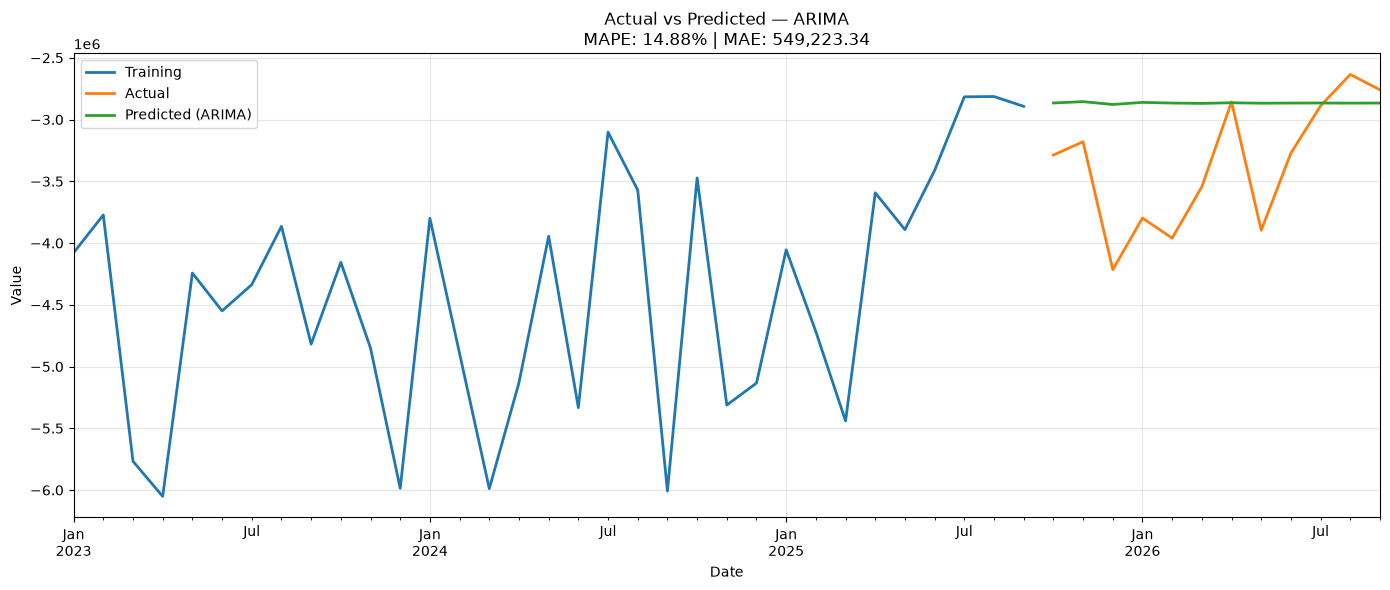

In [111]:
import matplotlib.pyplot as plt

# Create and train the selected model
best_model = BEST_MODEL_FACTORY()
best_model.fit(train_total)

# Predict the validation period
best_prediction = best_model.predict(len(validation_total))

# Plot actual vs predicted
plt.figure(figsize=(14, 6))
train_total.plot(label="Training", linewidth=2)
validation_total.plot(label="Actual", linewidth=2)
best_prediction.plot(label=f"Predicted ({BEST_MODEL_NAME})", linewidth=2)

plt.title(
    f"Actual vs Predicted — {BEST_MODEL_NAME}\n"
    f"MAPE: {mape(validation_total, best_prediction):.2f}% | "
    f"MAE: {mae(validation_total, best_prediction):,.2f}"
)
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Segments Series

In [ ]:
import numpy as np
import pandas as pd
from darts.metrics import mape, mae

all_results = []

for segment_name, ts in darts_series.items():
    if segment_name == "total":
        continue

    if len(ts) <= VALIDATION_HORIZON:
        print(f"Skipping {segment_name}: insufficient history")
        continue

    train_ts, actual_ts = ts.split_before(0.75)

    try:
        model = BEST_MODEL_FACTORY()
        model.fit(train_ts)
        prediction = model.predict(len(actual_ts))

        model_mape = float(mape(actual_ts, prediction))
        model_mae = float(mae(actual_ts, prediction))

        all_results.append({
            "Segment": segment_name,
            "Model": model_name,
            "MAPE (%)": model_mape,
            "MAE": model_mae,
            "Status": "OK",
            "Error": None,
        })

    except Exception as e:
        all_results.append({
            "Segment": segment_name,
            "Model": model_name,
            "MAPE (%)": np.nan,
            "MAE": np.nan,
            "Status": "Failed",
            "Error": str(e),
        })

results_df = pd.DataFrame(all_results)

print("Evaluation completed.")
print("Segments evaluated:", results_df["Segment"].nunique())
print("Candidate models:", len(candidate_models))
print("Total evaluations:", len(results_df))

In [87]:
valid_results = results_df[
    (results_df["Status"] == "OK")
    & np.isfinite(results_df["MAPE (%)"])
].copy()

best_indices = valid_results.groupby("Segment")["MAPE (%)"].idxmin()

best_models_df = (
    valid_results.loc[best_indices]
    .sort_values("Segment")
    .reset_index(drop=True)
)

print("Best model for each segment:")
display(
    best_models_df[
        ["Segment", "Model", "MAPE (%)", "MAE"]
    ].round(2)
)

Best model for each segment:


,Segment,Model,MAPE (%),MAE
0,7B01 | 3100 | PL01 | Sales Revenue,ARIMA,14.99,50803.21
1,7B01 | 4100 | PL01 | Sales Revenue,NaiveSeasonal,14.54,397850.76
2,7B01 | 5100 | PL01 | Sales Revenue,NaiveSeasonal,15.21,22327.71
3,7C01 | 1700 | PL01 | Sales Revenue,ARIMA,164.62,68663.30
4,7D01 | 1700 | PL01 | Sales Revenue,NaiveSeasonal,0.00,0.00
